# 10 · Beyond images: diffusion policies and planning

So far the "data" were points and pictures. In this notebook the data are **behaviours**:
trajectories of an agent that has to get past an obstacle. We will see that the property that
makes diffusion models good image generators (they represent complicated, *multimodal*
distributions) is exactly what imitation learning needs, and that the toolbox of the previous
notebooks (conditioning, few-step samplers, inpainting, guidance) becomes a toolbox for
decision making: closed-loop policies, goal-conditioned planning, and obeying constraints that
were never in the training data.

**You will learn:**
- why behaviour cloning by regression fails on multimodal demonstrations (it returns the
  posterior *mean*), and how a conditional diffusion model fixes this by *sampling*;
- how to build and train a **diffusion policy** that maps the current state to a chunk of future
  waypoints, and how the noisiest denoiser *is* the regression policy;
- how to run it **closed-loop** with receding-horizon replanning, and why that buys robustness
  to perturbations;
- **planning as inpainting** (Diffuser): an unconditional trajectory prior plus clamped start and goal;
- **cost guidance**: steering the learned prior around an obstacle it has never seen, and the
  guidance-strength trade-off;
- why the **prediction target** ($\varepsilon$, $v$ or $\tau_0$) matters here: it decides which
  noise levels the network cares about, and the route is chosen at low signal-to-noise ratio;
- practical details: few-step sampling for real-time control, $\hat\tau_0$ clipping, schedule
  choice, learning-rate decay, RePaint resampling, and CPU threading for tiny networks.

**Prerequisites:** 01–04 (forward process, DDPM, Tweedie, DDIM), 06 (conditioning, guidance),
07 (inpainting with the replacement trick).

**Runtime:** about 5–8 min on a 4-core CPU (mostly training three small MLPs), 1–3 min on a GPU.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.patches import Circle, Rectangle

import dmtools as dm

device = dm.get_device(verbose=True)
FAST = dm.fast_mode()  # automated smoke-test switch, leave as is
dm.seed_everything(0)
if device.type == "cpu":
    # Our networks are small MLPs. For them, multi-threaded BLAS spends more time
    # synchronising threads than computing; one thread is usually fastest (and on a
    # busy machine it can be >10x faster than the default).
    torch.set_num_threads(1)

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10,
                     "axes.labelsize": 9, "legend.fontsize": 8, "xtick.labelsize": 8,
                     "ytick.labelsize": 8})
# one colour per concept, used in every figure
COL = {"above": "tab:blue", "below": "tab:orange", "bc": "tab:red", "new": "tab:purple",
       "obstacle": "0.6", "start": "tab:green"}

# training budgets (FAST mode only checks that every code path runs)
BC_STEPS = 200 if FAST else 2000
DP_STEPS = 200 if FAST else 4000      # each diffusion policy
DIFFUSER_STEPS = 200 if FAST else 4000
N_DEMOS = 400 if FAST else 2000
N_EVAL = 200 if FAST else 1000        # starts used to compute metrics

Using device: cpu


## 1 · The task: imitating an expert who has two good answers

**Behaviour cloning (BC)** is supervised learning on expert data: from pairs (state $s$,
expert action $a$) fit a policy $\pi_\theta(a\mid s)$. Following *Diffusion Policy*
(Chi et al. 2023), our "action" is an **action chunk**: the next $H$ waypoints
$\tau = (w_1,\dots,w_H)\in\mathbb{R}^{H\times 2}$ the agent should visit.

The world is a plane with a disc obstacle at the origin. The agent starts somewhere in a box on
the left and has to reach the goal $G=(1,0)$ on the right. The expert's demonstrations are
smooth curves (cubic Bézier curves with random control points, traversed at constant speed,
plus a little waypoint jitter) that pass **above or below the obstacle with probability ½ each,
from every start**. So the distribution we want to imitate, $p(\tau\mid s)$, is bimodal for every
state $s$ in the start box.

This is not an artificial difficulty: human demonstrations are full of it. There are several
equally good ways to do most tasks, and different demonstrators (or the same one on different
days) choose differently.

In [2]:
H = 32                                        # waypoints per plan (the "action chunk")
OBST_C, OBST_R = np.array([0.0, 0.0]), 0.35   # the obstacle every demonstration avoids
GOAL = np.array([1.0, 0.0])
START_BOX = ((-1.1, -0.9), (-0.4, 0.4))       # (x-range, y-range) of start positions
CLIP = 1.5                                    # all coordinates of all plans lie in [-CLIP, CLIP]


def bezier(ctrl, n_pts=200):
    """Cubic Bezier curves for control points ctrl (N, 4, 2) -> (N, n_pts, 2)."""
    s = np.linspace(0.0, 1.0, n_pts)[None, :, None]
    p0, p1, p2, p3 = (ctrl[:, k, None, :] for k in range(4))
    return (1 - s) ** 3 * p0 + 3 * (1 - s) ** 2 * s * p1 + 3 * (1 - s) * s ** 2 * p2 + s ** 3 * p3


def resample_arclength(paths, n_pts):
    """Re-sample dense polylines (N, M, 2) at n_pts points equally spaced in arc length,
    i.e. the expert moves at constant speed along each demonstration."""
    seg = np.linalg.norm(np.diff(paths, axis=1), axis=-1)
    cum = np.concatenate([np.zeros((len(paths), 1)), seg.cumsum(1)], 1)
    out = np.empty((len(paths), n_pts, 2))
    for i in range(len(paths)):
        s = np.linspace(0.0, cum[i, -1], n_pts)
        out[i] = np.stack([np.interp(s, cum[i], paths[i, :, d]) for d in range(2)], 1)
    return out


def polyline_dist(paths, centre):
    """Distance from the point `centre` to each polyline in paths (N, L, 2), i.e. the minimum
    over its L-1 straight segments (checking waypoints alone would miss corner cutting)."""
    a, b = paths[:, :-1], paths[:, 1:]
    ab = b - a
    u = ((centre - a) * ab).sum(-1) / np.maximum((ab ** 2).sum(-1), 1e-12)
    closest = a + np.clip(u, 0.0, 1.0)[..., None] * ab
    return np.linalg.norm(closest - centre, axis=-1).min(1)


def make_demos(n, rng, start_box=START_BOX, goal_box=None, clearance=0.15, jitter=0.005):
    """n expert trajectories, shape (n, H+1, 2): the start followed by H waypoints.

    Each is a cubic Bezier curve whose two inner control points lie either above or below the
    obstacle (a fair coin decides), re-sampled at constant speed, plus a little waypoint jitter.
    Curves passing closer than `clearance` to the obstacle are redrawn (rejection sampling).
    goal_box=None uses the fixed GOAL; otherwise goals are uniform in the box.
    Returns (demos, route) with route = 1 for 'above' and 0 for 'below'.
    """
    demos, route = np.zeros((n, H + 1, 2)), np.zeros(n, dtype=int)
    todo = np.arange(n)
    while len(todo):
        m = len(todo)
        side = rng.choice([-1.0, 1.0], m)
        uni = lambda lo, hi: rng.uniform(lo, hi, m)   # noqa: E731
        p0 = np.stack([uni(*start_box[0]), uni(*start_box[1])], 1)
        p3 = (np.tile(GOAL, (m, 1)) if goal_box is None
              else np.stack([uni(*goal_box[0]), uni(*goal_box[1])], 1))
        p1 = np.stack([uni(-0.6, -0.3), side * uni(0.55, 0.95)], 1)
        p2 = np.stack([uni(0.3, 0.6), side * uni(0.55, 0.95)], 1)
        tr = resample_arclength(bezier(np.stack([p0, p1, p2, p3], 1)), H + 1)
        tr[:, 1:-1] += jitter * rng.standard_normal((m, H - 1, 2))   # endpoints stay exact
        ok = polyline_dist(tr, OBST_C) > OBST_R + clearance
        demos[todo[ok]], route[todo[ok]] = tr[ok], side[ok] > 0
        todo = todo[~ok]
    return demos, route


rng = np.random.default_rng(0)
demos, route = make_demos(N_DEMOS, rng)
steps = np.linalg.norm(np.diff(demos, axis=1), axis=-1)
clearance = polyline_dist(demos, OBST_C) - OBST_R
print(f"{len(demos)} demonstrations, {route.mean():.1%} go above the obstacle")
print(f"closest approach to the obstacle surface: {clearance.min():.3f}")
print(f"expert step length: mean {steps.mean():.3f}, range [{steps.min():.3f}, {steps.max():.3f}]")
assert (clearance > 0).all() and np.allclose(demos[:, -1], GOAL)

2000 demonstrations, 51.5% go above the obstacle
closest approach to the obstacle surface: 0.150
expert step length: mean 0.076, range [0.042, 0.113]


A few helpers for drawing the world and trajectories, used in every figure below.

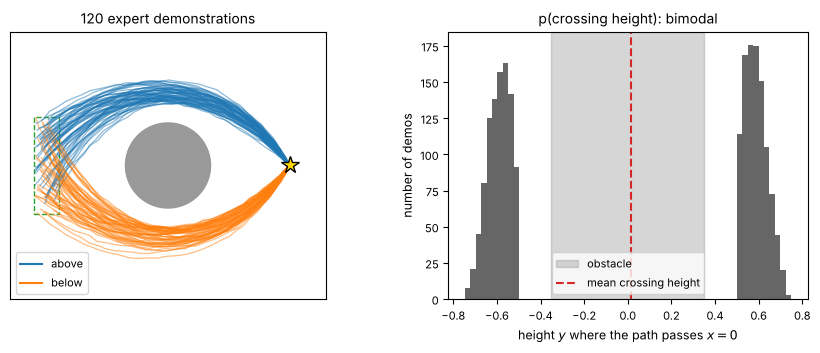

In [3]:
def draw_world(ax, extra_obstacles=(), title=None, start_box=START_BOX, goal=True):
    """Obstacle (grey disc), start region (dashed green box) and goal (star)."""
    ax.add_patch(Circle(OBST_C, OBST_R, color=COL["obstacle"], zorder=1))
    for c, r in extra_obstacles:
        ax.add_patch(Circle(c, r, color=COL["new"], alpha=0.7, zorder=1))
    if start_box is not None:
        (x0, x1), (y0, y1) = start_box
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ls="--", lw=1,
                               color=COL["start"]))
    if goal:
        ax.plot(*GOAL, marker="*", ms=13, color="gold", mec="k", zorder=6)
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.1, 1.1)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title)


def route_colours(paths):
    """Colour each path by the side on which it passes the obstacle."""
    i_mid = np.abs(paths[..., 0] - OBST_C[0]).argmin(1)          # waypoint level with the obstacle
    above = paths[np.arange(len(paths)), i_mid, 1] > OBST_C[1]
    return [COL["above"] if a else COL["below"] for a in above]


def plot_paths(ax, paths, colours=None, alpha=0.5, lw=0.9, **kw):
    """paths: (N, L, 2) numpy array of waypoint sequences."""
    colours = route_colours(paths) if colours is None else colours
    if isinstance(colours, str):
        colours = [colours] * len(paths)
    for p, c in zip(paths, colours):
        ax.plot(p[:, 0], p[:, 1], color=c, alpha=alpha, lw=lw, **kw)


fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
draw_world(axes[0], title="120 expert demonstrations")
plot_paths(axes[0], demos[:120])
axes[0].plot([], [], color=COL["above"], label="above")
axes[0].plot([], [], color=COL["below"], label="below")
axes[0].legend(loc="lower left")
# where do demonstrations cross the vertical line through the obstacle?
i_mid = np.abs(demos[..., 0] - OBST_C[0]).argmin(1)
y_cross = demos[np.arange(len(demos)), i_mid, 1]
axes[1].hist(y_cross, bins=60, color="0.4")
axes[1].axvspan(-OBST_R, OBST_R, color=COL["obstacle"], alpha=0.4, label="obstacle")
axes[1].axvline(y_cross.mean(), color=COL["bc"], ls="--", label="mean crossing height")
axes[1].set_xlabel("height $y$ where the path passes $x=0$")
axes[1].set_ylabel("number of demos")
axes[1].set_title("p(crossing height): bimodal")
axes[1].legend()
plt.tight_layout()
plt.show()

Two clean modes, and their mean lies *inside* the obstacle. Keep that red dashed line in mind.

### Training pairs: (state, next $H$ waypoints)

A policy must be queryable from *any* state the agent finds itself in, not only from the start.
So, as in Diffusion Policy, we cut every demonstration into training pairs: for each time step
$i$ the condition is the state $s = w_i$ and the target is the chunk
$\tau = (w_{i+1},\dots,w_{i+H})$. Beyond the end of a demonstration we pad with the goal
(the agent waits there). From the start state ($i=0$) the target is the whole demonstration.

*Gotcha:* the network sees a chunk as a flat vector of length $2H$ ordered
$(x_1, y_1, x_2, y_2, \dots)$. Flatten and un-flatten with the same convention everywhere
(`reshape(-1, H, 2)`), or you will silently train on scrambled trajectories.

training pairs: (64000, 2) -> (64000, 64)


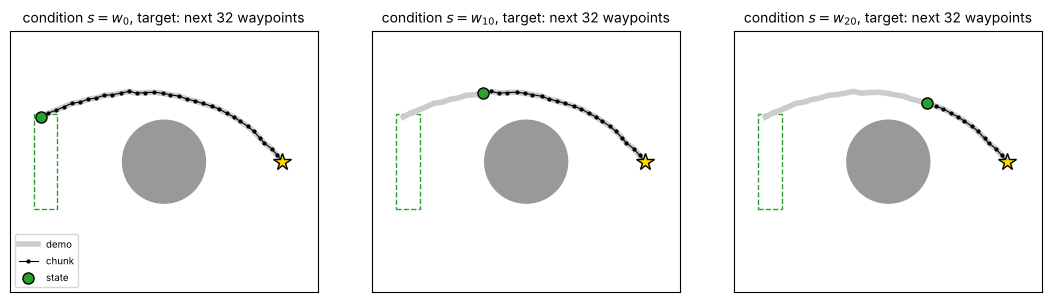

In [4]:
def make_windows(demos):
    """(state, next-H-waypoints) training pairs from every time step of every demo."""
    padded = np.concatenate([demos, np.repeat(demos[:, -1:], H, axis=1)], axis=1)
    states = np.concatenate([padded[:, i] for i in range(H)])
    chunks = np.concatenate([padded[:, i + 1:i + 1 + H] for i in range(H)])
    return states, chunks


def to_tensor(a):
    return torch.as_tensor(np.asarray(a), dtype=torch.float32, device=device)


def to_paths(x):
    """Flat plans (B, 2H) tensor -> (B, H, 2) numpy array."""
    return x.detach().reshape(x.shape[0], -1, 2).cpu().numpy()


win_states, win_chunks = make_windows(demos)
S_train = to_tensor(win_states)                  # (N, 2)  conditions
P_train = to_tensor(win_chunks).flatten(1)       # (N, 2H) targets
print("training pairs:", tuple(S_train.shape), "->", tuple(P_train.shape))

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, i in zip(axes, [0, 10, 20]):
    state, chunk = win_states[i * len(demos)], win_chunks[i * len(demos)]   # (demo 0, time i)
    draw_world(ax, title=f"condition $s=w_{{{i}}}$, target: next {H} waypoints")
    ax.plot(demos[0, :, 0], demos[0, :, 1], color="0.8", lw=4, zorder=2, label="demo")
    ax.plot(chunk[:, 0], chunk[:, 1], ".-", color="k", ms=4, lw=0.8, zorder=3, label="chunk")
    ax.plot(*state, "o", color=COL["start"], ms=8, mec="k", zorder=4, label="state")
axes[0].legend(loc="lower left", fontsize=7)
plt.tight_layout()
plt.show()

The chunk from $w_{20}$ reaches the goal after 12 steps and then "waits" there (the remaining
dots pile up on the star), so every target has the same length $H$.

## 2 · Baseline: behaviour cloning by regression

The obvious approach is to regress the chunk on the state with a squared loss,
$\min_f \mathbb{E}\,\lVert \tau - f(s)\rVert^2$. Its minimiser is the **conditional mean**:
for any $f$,

$$\mathbb{E}\lVert\tau-f(s)\rVert^2 = \mathbb{E}\lVert\tau-\mathbb{E}[\tau\mid s]\rVert^2
+ \mathbb{E}\lVert\mathbb{E}[\tau\mid s]-f(s)\rVert^2,$$

because the cross term $2\,\mathbb{E}\big[(\tau-\mathbb{E}[\tau|s])^\top(\mathbb{E}[\tau|s]-f(s))\big]$
vanishes once you condition on $s$. So $f^\star(s)=\mathbb{E}[\tau\mid s]$: the Bayes-optimal
point estimate under squared loss, the posterior mean. For our bimodal demonstrations,
$p(\tau\mid s)=\tfrac12 p_{\text{above}}(\tau\mid s)+\tfrac12 p_{\text{below}}(\tau\mid s)$, hence
$f^\star(s)=\tfrac12(\mu_{\text{above}}+\mu_{\text{below}})$: a path through the middle. The
posterior mean of a bimodal posterior is a value the posterior itself considers nearly
impossible. Averaging two good actions gives a bad one whenever the set of good actions is not
convex, which is the usual situation in control.

In [5]:
class BCPolicy(nn.Module):
    """Deterministic behaviour cloning: state (B, 2) -> flat chunk (B, 2H)."""

    def __init__(self, hidden=256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2, hidden), nn.SiLU(), nn.Linear(hidden, hidden),
                                 nn.SiLU(), nn.Linear(hidden, hidden), nn.SiLU(),
                                 nn.Linear(hidden, 2 * H))

    def forward(self, s):
        return self.net(s)


def train_regression(model, X, Y, steps, batch_size=256, lr=1e-3):
    """Plain MSE regression with Adam and a cosine learning-rate decay."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched_lr = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for step in range(steps):
        idx = torch.randint(0, len(X), (batch_size,), device=X.device)
        loss = F.mse_loss(model(X[idx]), Y[idx])
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        sched_lr.step()
        if (step + 1) % (steps // 4) == 0:
            print(f"step {step + 1:5d} | mse {loss.item():.4f}")
    return model.eval()


t0 = time.time()
bc = train_regression(BCPolicy().to(device), S_train, P_train, BC_STEPS)
print(f"BC trained in {time.time() - t0:.0f} s")

step   500 | mse 0.0117


step  1000 | mse 0.0122


step  1500 | mse 0.0109


step  2000 | mse 0.0108
BC trained in 12 s


**Check.** Because we own the data generator we can compute $\mathbb{E}[\tau\mid s]$ by Monte
Carlo: draw thousands of fresh demonstrations from one fixed start $s^\ast$ and average them. The
regression network should reproduce that average.

In [6]:
s_star = np.array([-1.0, 0.1])
fresh, fresh_route = make_demos(4000, np.random.default_rng(1),
                                start_box=((s_star[0],) * 2, (s_star[1],) * 2))
mc_mean = fresh[:, 1:].mean(0)                                  # E[tau | s*], (H, 2)
with torch.no_grad():
    bc_plan = to_paths(bc(to_tensor(s_star[None])))[0]
rms = np.sqrt(((bc_plan - mc_mean) ** 2).sum(-1).mean())
print(f"RMS distance BC(s*) vs Monte-Carlo E[tau|s*]: {rms:.3f}   "
      f"(distance between the two route means: "
      f"{np.sqrt(((fresh[fresh_route == 1, 1:].mean(0) - fresh[fresh_route == 0, 1:].mean(0)) ** 2).sum(-1).mean()):.2f})")

RMS distance BC(s*) vs Monte-Carlo E[tau|s*]: 0.066   (distance between the two route means: 0.83)


The network has learned the conditional mean (the RMS error is small compared with the distance
between the two route means). Now let's measure what that means for behaviour. For a batch of
plans we report the **collision rate** (any segment of start → $w_1$ → … → $w_H$ entering the
obstacle), the **fraction routed above**, the **goal error** $\lVert w_H - G\rVert$, and a
**roughness** score (the mean squared second difference of the waypoints, averaged over plans:
smooth expert curves score low, jittery or kinked plans score high), and a **spread** score (the
standard deviation of the crossing height *within* each route, averaged over the two routes: it
measures diversity, which a good imitator should match, not minimise).

expert demonstrations         collision 0.000  above 0.515  goal err 0.000  roughness  0.0003  spread 0.052
BC regression                 collision 0.840  above 0.530  goal err 0.007  roughness  0.0009  spread 0.129


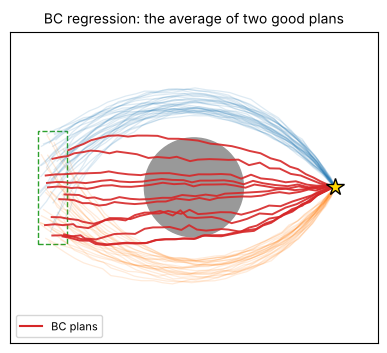

In [7]:
def plan_metrics(starts, paths, obstacles=((OBST_C, OBST_R),), goals=GOAL):
    """Summary statistics for plans paths (N, H, 2) that start at starts (N, 2)."""
    full = np.concatenate([starts[:, None], paths], 1)
    hit = np.zeros(len(full), dtype=bool)
    for c, r in obstacles:
        hit |= polyline_dist(full, c) < r
    above = np.array(route_colours(full)) == COL["above"]
    goal_err = np.linalg.norm(full[:, -1] - goals, axis=-1)
    rough = (np.diff(full, 2, axis=1) ** 2).sum(-1).mean(1)
    i_mid = np.abs(full[..., 0] - OBST_C[0]).argmin(1)
    y_cross = full[np.arange(len(full)), i_mid, 1]
    spread = np.mean([y_cross[m].std() for m in (above, ~above) if m.sum() > 1])
    return {"collision": hit.mean(), "above": above.mean(), "goal err": goal_err.mean(),
            "roughness": rough.mean(), "spread": spread}


def print_metrics(name, m):
    print(f"{name:30s}" + "  ".join(f"{k} {v:7.4f}" if k == "roughness" else f"{k} {v:5.3f}"
                                     for k, v in m.items() if k != "ms"))


eval_starts = np.stack([np.random.default_rng(2).uniform(*START_BOX[0], N_EVAL),
                        np.random.default_rng(3).uniform(*START_BOX[1], N_EVAL)], 1)
with torch.no_grad():
    bc_paths = to_paths(bc(to_tensor(eval_starts)))
print_metrics("expert demonstrations", plan_metrics(demos[:, 0], demos[:, 1:]))
print_metrics("BC regression", plan_metrics(eval_starts, bc_paths))

fig, ax = plt.subplots(figsize=(4.6, 3.6))
draw_world(ax, title="BC regression: the average of two good plans")
plot_paths(ax, demos[:60], alpha=0.15)
plot_paths(ax, bc_paths[:12], colours=COL["bc"], alpha=0.9, lw=1.4)
ax.plot([], [], color=COL["bc"], label="BC plans")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

Exactly as predicted: BC plans (red) are smooth, end at the goal, and drive straight through the
obstacle, nearly every time. More data or a bigger network cannot fix this; the *loss* asks for
the mean. (Classical fixes are mixture-density outputs, discretised actions, or energy-based
"implicit" policies. Diffusion has proved one of the most effective, especially for
high-dimensional action chunks.)

## 3 · Diffusion policy: sample from $p(\tau\mid s)$

We train a conditional DDPM over chunks, exactly as in notebook 02 except that the network also
receives the state:

$$\mathcal{L}(\theta)=\mathbb{E}_{(s,\tau_0),\,t,\,\varepsilon}\Big\lVert\varepsilon-
\varepsilon_\theta\big(\sqrt{\bar\alpha_t}\,\tau_0+\sqrt{1-\bar\alpha_t}\,\varepsilon,\;t,\;s\big)\Big\rVert^2 .$$

The optimum is $\varepsilon^\ast=\mathbb{E}[\varepsilon\mid\tau_t,s]$, and Tweedie's formula
(notebook 03) turns it into a posterior mean of the clean chunk,

$$\hat\tau_0(\tau_t,t,s)=\frac{\tau_t-\sqrt{1-\bar\alpha_t}\,\varepsilon^\ast}{\sqrt{\bar\alpha_t}}
=\mathbb{E}[\tau_0\mid\tau_t,s].$$

Here is the punchline. **The denoiser is also a regression**, but of $\tau_0$ on $(\tau_t,s)$
instead of on $s$ alone. At the largest noise level $\tau_t$ carries almost no information about
$\tau_0$, so $\hat\tau_0\approx\mathbb{E}[\tau_0\mid s]$: *the noisiest denoiser is the BC
regressor of Section 2.* As $t$ decreases, $\tau_t$ increasingly reveals which route the sample
is heading for, and $\mathbb{E}[\tau_0\mid\tau_t,s]$ becomes a unimodal, easy regression. The
sampler chains many such regressions, and the chain represents a multimodal distribution that no
single regression can.

**Architecture.** A residual MLP over the flat chunk. The time embedding plus a learned
embedding of the state modulate every block by FiLM (feature-wise scale and shift after a
LayerNorm, the "adaLN" of DiT); the raw state is also concatenated to the input. Diffusion Policy
itself uses a 1-D temporal U-Net or a transformer; for $2H=64$ numbers an MLP is enough and
trains in minutes on a CPU.

In [8]:
class TrajectoryDenoiser(nn.Module):
    """Denoiser for flat trajectories x_t (B, D), optionally conditioned on a continuous vector
    s (B, cond_dim); cond_dim=0 gives an unconditional model. Whether the output means eps, v
    or x0 is decided by the training loss."""

    def __init__(self, data_dim, cond_dim=2, hidden=256, n_blocks=3, emb_dim=64):
        super().__init__()
        self.cond_dim = cond_dim
        self.time_emb = nn.Sequential(dm.SinusoidalEmbedding(emb_dim), nn.Linear(emb_dim, hidden),
                                      nn.SiLU(), nn.Linear(hidden, hidden))
        self.cond_emb = (nn.Sequential(nn.Linear(cond_dim, hidden), nn.SiLU(),
                                       nn.Linear(hidden, hidden)) if cond_dim else None)
        self.inp = nn.Linear(data_dim + cond_dim, hidden)
        self.norms = nn.ModuleList([nn.LayerNorm(hidden, elementwise_affine=False)
                                    for _ in range(n_blocks)])
        self.films = nn.ModuleList([nn.Linear(hidden, 2 * hidden) for _ in range(n_blocks)])
        self.mlps = nn.ModuleList([nn.Sequential(nn.Linear(hidden, hidden), nn.SiLU(),
                                                 nn.Linear(hidden, hidden))
                                   for _ in range(n_blocks)])
        self.out = nn.Sequential(nn.LayerNorm(hidden), nn.SiLU(), nn.Linear(hidden, data_dim))

    def forward(self, x, t, y=None):
        emb = self.time_emb(t)
        if self.cond_emb is not None:                 # y = the state we condition on
            emb = emb + self.cond_emb(y)
            x = torch.cat([x, y], dim=1)
        emb = F.silu(emb)
        h = self.inp(x)
        for norm, film, mlp in zip(self.norms, self.films, self.mlps):
            scale, shift = film(emb).chunk(2, dim=1)
            h = h + mlp(norm(h) * (1 + scale) + shift)
        return self.out(h)

### Which target should the network predict?

Besides $\varepsilon$, the network can be trained to output the clean chunk $\tau_0$, or the
"velocity" $v=\sqrt{\bar\alpha_t}\,\varepsilon-\sqrt{1-\bar\alpha_t}\,\tau_0$ (Salimans & Ho 2022).
All three are interchangeable at a fixed $t$, e.g.
$\hat\varepsilon=(\tau_t-\sqrt{\bar\alpha_t}\,\hat\tau_0)/\sqrt{1-\bar\alpha_t}$ and
$\hat\tau_0=\sqrt{\bar\alpha_t}\,\tau_t-\sqrt{1-\bar\alpha_t}\,\hat v$, and all are minimised by
the posterior mean. What differs is **how the loss weights the noise levels**. Substituting,

$$\varepsilon-\hat\varepsilon=\sqrt{\tfrac{\bar\alpha_t}{1-\bar\alpha_t}}\,(\hat\tau_0-\tau_0),
\qquad v-\hat v=\tfrac{1}{\sqrt{1-\bar\alpha_t}}\,(\hat\tau_0-\tau_0),$$

so with $\mathrm{SNR}_t=\bar\alpha_t/(1-\bar\alpha_t)$,

$$\lVert\varepsilon-\hat\varepsilon\rVert^2=\mathrm{SNR}_t\,\lVert\tau_0-\hat\tau_0\rVert^2,\qquad
\lVert v-\hat v\rVert^2=(1+\mathrm{SNR}_t)\,\lVert\tau_0-\hat\tau_0\rVert^2,\qquad
\lVert\tau_0-\hat\tau_0\rVert^2 = 1\cdot\lVert\tau_0-\hat\tau_0\rVert^2 .$$

The SNR spans about eight orders of magnitude over our schedule. **$\varepsilon$-prediction**
pours its effort into low-noise levels (fine detail, what matters for image quality) and barely
cares about high-noise levels. But for our task the important event, choosing a route, happens
at low SNR (we will see exactly where), and there an $\varepsilon$-network's $\hat\tau_0$ is its
output error magnified by $1/\sqrt{\bar\alpha_t}$. **$\tau_0$-prediction** has the opposite
bias: it under-weights low noise levels, where the fine, within-route detail is learned.
**$v$-prediction** weights like $\tau_0$-prediction at high noise and like
$\varepsilon$-prediction at low noise. A big network can afford to be precise everywhere; a small
one has to choose. We train the standard $\varepsilon$-model and a $v$-model with identical
networks and budgets, and compare. (Exercise 4: the $\tau_0$-model.)

**Other practical details.**

* *Continuous conditioning through dmtools.* `dm.diffusion_loss`, `dm.model_predictions` and
  `dm.ddim_sample` simply pass their `y` argument on to `model(x, t, y)`, so a float tensor of
  states works as long as we do not ask for classifier-free guidance (that path assumes integer
  class labels).
* *Few noise levels.* Like Diffusion Policy we train with only $T=100$ noise levels and sample
  with 10–20 steps, because a controller has to answer in milliseconds.
* *Schedule.* The cosine schedule clamps its last $\beta$ at 0.999, which makes $\bar\alpha_{T-1}$
  tiny. With $\varepsilon$-prediction the first sampling step then computes
  $\hat\tau_0=(\tau_T-\sqrt{1-\bar\alpha}\,\hat\varepsilon)/\sqrt{\bar\alpha}$, amplifying the
  network's error by $1/\sqrt{\bar\alpha_{T-1}}$ (printed below); in our tests that produced
  plans with goal errors of 100+ units. We use the linear schedule.
* *Clipping.* The workspace is bounded, so we clip $\hat\tau_0$ to $[-1.5,1.5]$ at every sampling
  step, just as images are clipped to $[-1,1]$.
* *Learning-rate decay.* Waypoints must be precise to a few hundredths. `dm.train_diffusion` keeps
  the learning rate constant (fine for images, where EMA does the averaging); here a cosine
  decay to zero made the plans 3–5 times smoother at equal cost in our tests. So we write the
  loop out, reusing `dm.diffusion_loss` and `dm.EMA` from notebooks 02 and 05.

In [9]:
for kind in ["linear", "cosine"]:
    s_ = dm.NoiseSchedule(T=100, kind=kind)
    print(f"{kind:6s}: alpha_bar[T-1] = {s_.alpha_bars[-1].item():.2e}  ->  error amplification "
          f"1/sqrt(alpha_bar) = {1 / s_.alpha_bars[-1].sqrt().item():6.0f}")

sched = dm.NoiseSchedule(T=100, kind="linear", device=device)
snr = sched.snr(torch.arange(sched.T))
print(f"SNR_t ranges from {snr[0].item():.1e} (t=0) to {snr[-1].item():.1e} (t={sched.T - 1})")


def train_denoiser(model, X, cond=None, pred="v", steps=4000, batch_size=128, lr=2e-3,
                   warmup=200):
    """Diffusion training (target `pred` = 'eps', 'v' or 'x0') with AdamW, warm-up + cosine
    learning-rate decay, gradient clipping, and an EMA copy of the weights to sample with."""
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    lr_at = lambda s: min(1.0, (s + 1) / warmup) * 0.5 * (1 + np.cos(np.pi * s / steps))  # noqa: E731
    sched_lr = torch.optim.lr_scheduler.LambdaLR(opt, lr_at)
    ema = dm.EMA(model, decay=0.999)
    losses, t0 = [], time.time()
    for step in range(steps):
        idx = torch.randint(0, len(X), (batch_size,), device=X.device)
        loss = dm.diffusion_loss(model, X[idx], sched, y=None if cond is None else cond[idx],
                                 pred=pred)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched_lr.step()
        ema.update(model)
        losses.append(loss.item())
        if (step + 1) % max(steps // 4, 1) == 0:
            print(f"  step {step + 1:5d} | {pred}-loss {np.mean(losses[-200:]):.4f}")
    print(f"  trained in {time.time() - t0:.0f} s")
    return ema.model.eval()


policies = {}
for pred in ["eps", "v"]:
    dm.seed_everything(0)
    net = TrajectoryDenoiser(2 * H, cond_dim=2).to(device)
    print(f"diffusion policy, {pred}-prediction ({dm.count_params(net) / 1e3:.0f}k parameters):")
    policies[pred] = train_denoiser(net, P_train, S_train, pred=pred, steps=DP_STEPS)

linear: alpha_bar[T-1] = 2.04e-05  ->  error amplification 1/sqrt(alpha_bar) =    221
cosine: alpha_bar[T-1] = 2.43e-07  ->  error amplification 1/sqrt(alpha_bar) =   2029
SNR_t ranges from 1.0e+03 (t=0) to 2.0e-05 (t=99)
diffusion policy, eps-prediction (973k parameters):


  step  1000 | eps-loss 0.0230


  step  2000 | eps-loss 0.0129


  step  3000 | eps-loss 0.0072


  step  4000 | eps-loss 0.0053
  trained in 106 s
diffusion policy, v-prediction (973k parameters):


  step  1000 | v-loss 0.0293


  step  2000 | v-loss 0.0180


  step  3000 | v-loss 0.0120


  step  4000 | v-loss 0.0101
  trained in 104 s


**Check.** The reweighting identities, on a real batch. For the $\varepsilon$-network, the
per-sample $\varepsilon$-error must equal $\mathrm{SNR}_t$ times the error of its implied
$\hat\tau_0$, and the error of its implied $\hat v$ must equal $(1+\mathrm{SNR}_t)$ times it.

In [10]:
idx = torch.randint(0, len(P_train), (512,), device=device)
t_chk = torch.randint(0, sched.T, (512,), device=device)
tau0, noise = P_train[idx], torch.randn_like(P_train[idx])
x_t = sched.q_sample(tau0, t_chk, noise)
with torch.no_grad():
    eps_hat, x0_hat = dm.model_predictions(policies["eps"], x_t, t_chk, sched, y=S_train[idx])
sa = sched.sqrt_alpha_bars[t_chk][:, None]
s1a = sched.sqrt_one_minus_alpha_bars[t_chk][:, None]
x0_err = ((tau0 - x0_hat) ** 2).sum(1)
eps_err = ((noise - eps_hat) ** 2).sum(1)
v_err = (((sa * noise - s1a * tau0) - (sa * eps_hat - s1a * x0_hat)) ** 2).sum(1)
snr_chk = sched.snr(t_chk)
print("eps identity, max rel. error:", ((eps_err - snr_chk * x0_err).abs() / eps_err).max().item())
print("v   identity, max rel. error:", ((v_err - (1 + snr_chk) * x0_err).abs() / v_err).max().item())
assert torch.allclose(eps_err, snr_chk * x0_err, rtol=1e-3)
assert torch.allclose(v_err, (1 + snr_chk) * x0_err, rtol=1e-3)

eps identity, max rel. error: 1.3040084013482556e-05
v   identity, max rel. error: 1.3027043678448536e-05


### A sampler with hooks

We write DDIM out once more because Sections 5 and 6 need to intervene inside the loop. Each
step converts the network output into $\hat\tau_0$ (Tweedie for $\varepsilon$; see above for $v$),
optionally edits it (clip; cost guidance), recomputes the $\hat\varepsilon$ that is consistent
with the edited $\hat\tau_0$, and jumps to the next noise level (notebook 04),

$$\tau_{t'}=\sqrt{\bar\alpha_{t'}}\,\hat\tau_0+\sqrt{1-\bar\alpha_{t'}-\sigma^2}\;\hat\varepsilon+\sigma z,
\qquad \sigma=\eta\sqrt{\tfrac{1-\bar\alpha_{t'}}{1-\bar\alpha_t}\big(1-\tfrac{\bar\alpha_t}{\bar\alpha_{t'}}\big)} .$$

$\eta=0$ is the deterministic DDIM ODE, $\eta=1$ is DDPM-like. The inpainting hook overwrites
known coordinates after each step (Section 5 explains it and the `resample` option). With
$\eta=0$ and no hooks the sampler must agree with `dm.ddim_sample`, and we check that for both
parameterisations.

In [11]:
def ddim_timesteps(T, n_steps):
    """Descending unique integer noise levels from T-1 to 0 (the same grid as dmtools)."""
    return [int(t) for t in np.unique(np.linspace(0, T - 1, n_steps).round())[::-1]]


def cost_gradient(cost_fn, x0):
    """d cost / d x0 for a batch of flat plans (autograd; the cost is summed over the batch)."""
    with torch.enable_grad():
        z = x0.detach().requires_grad_(True)
        (g,) = torch.autograd.grad(cost_fn(z).sum(), z)
    return g


@torch.no_grad()
def sample_plans(model, cond=None, n=None, *, pred="v", n_steps=20, eta=1.0, clip=CLIP,
                 x_T=None, dim=2 * H, cost_fn=None, guide=0.0, known=None, known_mask=None,
                 resample=1, return_x0=False):
    """DDIM over flat plans for model(x, t, cond), which predicts `pred` ('eps', 'v', 'x0').

    cost_fn, guide     : after predicting x0_hat, take a gradient step  x0_hat -= guide * grad C
    known, known_mask  : replacement-trick inpainting; coordinates where known_mask is True
                         are overwritten with a correctly-noised copy of `known` after each step
    resample           : RePaint-style harmonisation; repeat each step this many times, re-noising
                         back to the current level in between
    return_x0          : also return the list of x0_hat predictions (one per step, on CPU)
    """
    B = cond.shape[0] if cond is not None else n
    x = torch.randn(B, dim, device=device) if x_T is None else x_T.to(device)
    ts = ddim_timesteps(sched.T, n_steps)
    x0_hist = []
    for i, t in enumerate(ts):
        ab = sched.alpha_bars[t]
        ab_next = sched.alpha_bars[ts[i + 1]] if i + 1 < len(ts) else torch.ones((), device=device)
        for r in range(resample if i + 1 < len(ts) else 1):
            if r > 0:                         # RePaint: diffuse back from level t' to level t
                x = (ab / ab_next).sqrt() * x + (1 - ab / ab_next).sqrt() * torch.randn_like(x)
            out = model(x, torch.full((B,), t, device=device, dtype=torch.long), cond)
            if pred == "eps":
                x0 = (x - (1 - ab).sqrt() * out) / ab.sqrt()       # Tweedie
            elif pred == "v":
                x0 = ab.sqrt() * x - (1 - ab).sqrt() * out
            else:
                x0 = out
            if clip is not None:
                x0 = x0.clamp(-clip, clip)
            if cost_fn is not None and guide > 0:
                x0 = x0 - guide * cost_gradient(cost_fn, x0)
            eps = (x - ab.sqrt() * x0) / (1 - ab).sqrt()           # consistent with edited x0
            sigma = eta * ((1 - ab_next) / (1 - ab) * (1 - ab / ab_next)).sqrt()
            x = ab_next.sqrt() * x0 + (1 - ab_next - sigma ** 2).clamp(min=0).sqrt() * eps
            if eta > 0:
                x = x + sigma * torch.randn_like(x)
            if known is not None:
                noisy_known = ab_next.sqrt() * known + (1 - ab_next).sqrt() * torch.randn_like(known)
                x = torch.where(known_mask, noisy_known, x)
        if return_x0:
            x0_hist.append(x0.cpu())
    return (x, x0_hist) if return_x0 else x


# check against the dmtools implementation from notebook 04
cond_chk = to_tensor(eval_starts[:64])
xT_chk = torch.randn(64, 2 * H, device=device)
for pred, net in policies.items():
    ours = sample_plans(net, cond_chk, pred=pred, n_steps=10, eta=0.0, x_T=xT_chk)
    ref = dm.ddim_sample(net, sched, xT_chk.shape, n_steps=10, y=cond_chk, clip_x0=CLIP,
                         x_T=xT_chk, pred=pred)
    print(f"{pred:3s}: max |ours - dm.ddim_sample| = {(ours - ref).abs().max().item():.1e}")
    assert torch.allclose(ours, ref, atol=1e-4)

eps: max |ours - dm.ddim_sample| = 1.8e-06
v  : max |ours - dm.ddim_sample| = 1.2e-06


Now the real test: sample plans from the same random starts we used for BC.

expert demonstrations         collision 0.000  above 0.515  goal err 0.000  roughness  0.0003  spread 0.052
BC regression                 collision 0.840  above 0.530  goal err 0.007  roughness  0.0009  spread 0.129


diffusion policy, eps-pred    collision 0.132  above 0.494  goal err 0.010  roughness  0.0006  spread 0.162


diffusion policy, v-pred      collision 0.016  above 0.498  goal err 0.012  roughness  0.0011  spread 0.071


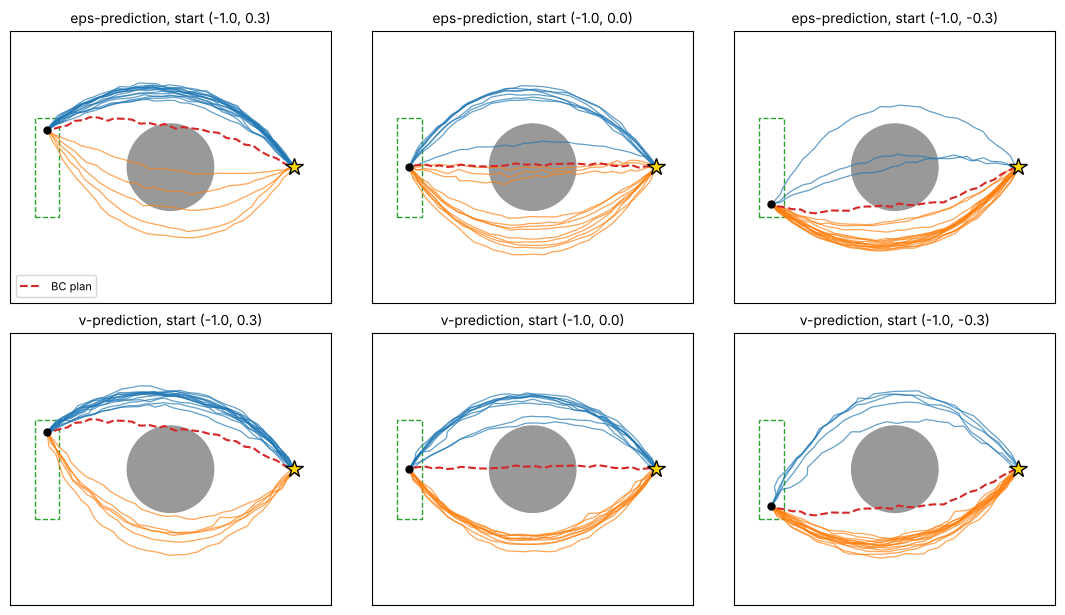

In [12]:
N_STEPS_POLICY = 20                     # sampling steps (eta = 1) used for control from here on
dp_paths = {}
print_metrics("expert demonstrations", plan_metrics(demos[:, 0], demos[:, 1:]))
print_metrics("BC regression", plan_metrics(eval_starts, bc_paths))
for pred, net in policies.items():
    torch.manual_seed(0)
    dp_paths[pred] = to_paths(sample_plans(net, to_tensor(eval_starts), pred=pred,
                                           n_steps=N_STEPS_POLICY))
    print_metrics(f"diffusion policy, {pred}-pred", plan_metrics(eval_starts, dp_paths[pred]))

show_starts = np.array([[-1.0, 0.3], [-1.0, 0.0], [-1.0, -0.3]])
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))
for row, (pred, net) in enumerate(policies.items()):
    for ax, s in zip(axes[row], show_starts):
        cond = to_tensor(np.repeat(s[None], 20, 0))
        torch.manual_seed(0)
        paths = to_paths(sample_plans(net, cond, pred=pred, n_steps=N_STEPS_POLICY))
        with torch.no_grad():
            bc_p = to_paths(bc(cond[:1]))[0]
        draw_world(ax, title=f"{pred}-prediction, start ({s[0]:.1f}, {s[1]:.1f})")
        plot_paths(ax, np.concatenate([np.repeat(s[None, None], 20, 0), paths], 1), alpha=0.7)
        ax.plot(bc_p[:, 0], bc_p[:, 1], "--", color=COL["bc"], lw=1.5, label="BC plan")
        ax.plot(*s, "o", color="k", ms=5, zorder=5)
axes[0, 0].legend(loc="lower left")
plt.tight_layout()
plt.show()

policy = policies["v"]           # the policy we use from now on

(20 samples per start.) From each start the diffusion policies produce plans along *both* routes, in roughly the
experts' 50/50 proportion (a "probability-matching" policy, in the language of decision making),
while the BC plan (dashed red) splits the difference. With the same network and training budget,
the $v$-model is clearly better where it matters: far fewer plans cut through or graze the
obstacle, and its spread is much closer to the experts'. The $\varepsilon$-model's failures are
exactly the low-SNR kind: plans that never properly decided between the routes (they also
inflate its spread), while its committed plans are, if anything, *smoother*: it spends its
capacity on low-noise detail. Neither model is perfect, and both improve with more training and
a bigger network. We use the $v$-model from now on.

### Watching the policy make up its mind

Let's verify the punchline of the maths. Below, 16 samples from one start, and the model's
running guess $\hat\tau_0$ at a few points of the reverse process (20 steps; dashed red = BC plan).

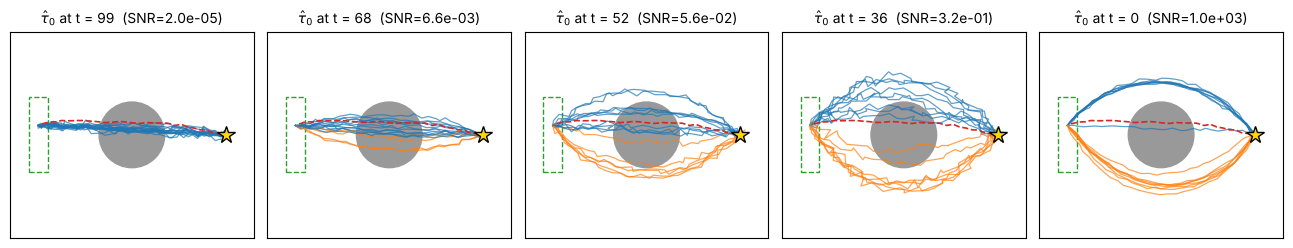

In [13]:
torch.manual_seed(1)
cond = to_tensor(np.repeat(s_star[None], 16, 0))
_, x0_hist = sample_plans(policy, cond, n_steps=20, return_x0=True)
ts20 = ddim_timesteps(sched.T, 20)
frames = [0, 6, 9, 12, 19]
fig, axes = plt.subplots(1, len(frames), figsize=(13, 2.8))
for ax, k in zip(axes, frames):
    paths = np.concatenate([np.repeat(s_star[None, None], 16, 0), to_paths(x0_hist[k])], 1)
    ab = sched.alpha_bars[ts20[k]].item()
    draw_world(ax, title=f"$\\hat\\tau_0$ at t = {ts20[k]}  (SNR={ab / (1 - ab):.1e})")
    plot_paths(ax, paths, alpha=0.7)
    ax.plot(bc_plan[:, 0], bc_plan[:, 1], "--", color=COL["bc"], lw=1.2)
plt.tight_layout()
plt.show()

At the highest noise level every sample's $\hat\tau_0$ lies on top of the BC plan: the noisiest
denoiser *is* the regression policy, mean path through the obstacle included. As the SNR grows
past roughly $10^{-2}$ the guesses peel away from the mean towards one route or the other, and
by $\mathrm{SNR}\approx 0.3$ each sample has committed and is merely being refined. The route is
chosen at low SNR, which is exactly where $\varepsilon$-prediction puts little weight
(Exercise 6 shows what this figure looks like for the $\varepsilon$-model).

**Check (tower property).** Averaging Tweedie's estimate over the noise gives back the BC answer
at *every* noise level,
$\mathbb{E}_{\tau_t\mid s}\big[\mathbb{E}[\tau_0\mid\tau_t,s]\big]=\mathbb{E}[\tau_0\mid s]$, even
though individual estimates at low noise are far from it. We noise the fresh demonstrations from
$s^\ast$, denoise them in one shot with the network, and compare.

In [14]:
fresh_flat = to_tensor(fresh[:, 1:]).flatten(1)
cond = to_tensor(np.repeat(s_star[None], len(fresh_flat), 0))
torch.manual_seed(0)
for t in [5, 30, 60, 90]:
    tt = torch.full((len(fresh_flat),), t, device=device, dtype=torch.long)
    with torch.no_grad():
        _, x0_hat = dm.model_predictions(policy, sched.q_sample(fresh_flat, tt), tt, sched,
                                         y=cond, pred="v")
    avg = x0_hat.mean(0).reshape(H, 2).cpu().numpy()
    single = x0_hat.reshape(-1, H, 2).cpu().numpy()
    print(f"t = {t:2d}: RMS(average x0_hat - MC mean) = {np.sqrt(((avg - mc_mean) ** 2).sum(-1).mean()):.3f}"
          f"   RMS(average x0_hat - BC) = {np.sqrt(((avg - bc_plan) ** 2).sum(-1).mean()):.3f}"
          f"   mean RMS(single x0_hat - BC) = {np.sqrt(((single - bc_plan) ** 2).sum(-1).mean(1)).mean():.3f}")

t =  5: RMS(average x0_hat - MC mean) = 0.016   RMS(average x0_hat - BC) = 0.064   mean RMS(single x0_hat - BC) = 0.406
t = 30: RMS(average x0_hat - MC mean) = 0.027   RMS(average x0_hat - BC) = 0.064   mean RMS(single x0_hat - BC) = 0.366


t = 60: RMS(average x0_hat - MC mean) = 0.042   RMS(average x0_hat - BC) = 0.050   mean RMS(single x0_hat - BC) = 0.116
t = 90: RMS(average x0_hat - MC mean) = 0.027   RMS(average x0_hat - BC) = 0.062   mean RMS(single x0_hat - BC) = 0.066


The *average* denoised chunk agrees with both the Monte-Carlo mean and the BC network to within a
few hundredths at every noise level. *Individual* denoised chunks agree with BC only at high
noise; at low noise they are far from it, on one route or the other. Diffusion and regression
agree on the mean; only diffusion gets the distribution right.

### How many denoising steps does a controller need?

A policy runs inside a control loop, so every network evaluation (NFE) is latency. Let's sweep
the number of DDIM steps and measure plan quality and wall-clock time per batch.

$v$-pred, $\eta$=0           collision rate vs steps: 2:0.884 3:0.596 5:0.236 10:0.116 20:0.064 50:0.048 100:0.043


$v$-pred, $\eta$=1           collision rate vs steps: 2:0.883 3:0.610 5:0.268 10:0.076 20:0.016 50:0.012 100:0.006


$\varepsilon$-pred, $\eta$=1 collision rate vs steps: 2:0.978 3:0.563 5:0.315 10:0.194 20:0.132 50:0.113 100:0.086


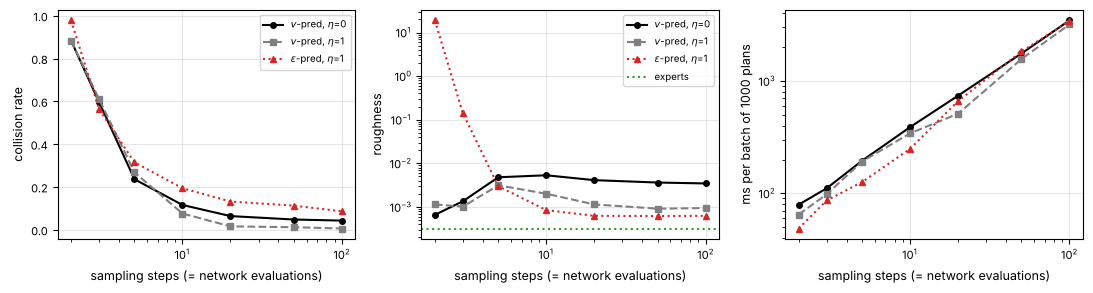

In [15]:
nfe_list = [2, 3, 5, 10, 20, 50, 100]
variants = {r"$v$-pred, $\eta$=0": ("v", 0.0), r"$v$-pred, $\eta$=1": ("v", 1.0),
            r"$\varepsilon$-pred, $\eta$=1": ("eps", 1.0)}
nfe_res = {name: [] for name in variants}
cond_eval = to_tensor(eval_starts)
for name, (pred, eta) in variants.items():
    for n_steps in nfe_list:
        torch.manual_seed(0)
        t0 = time.time()
        paths = to_paths(sample_plans(policies[pred], cond_eval, pred=pred, n_steps=n_steps, eta=eta))
        nfe_res[name].append({**plan_metrics(eval_starts, paths), "ms": 1e3 * (time.time() - t0)})
    print(f"{name:28s} collision rate vs steps: " +
          " ".join(f"{n}:{r['collision']:.3f}" for n, r in zip(nfe_list, nfe_res[name])))

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
styles = ["o-", "s--", "^:"]
colours = ["k", "0.5", COL["bc"]]
for ax, key, lab in zip(axes, ["collision", "roughness", "ms"],
                        ["collision rate", "roughness", f"ms per batch of {N_EVAL} plans"]):
    for (name, res), st, c in zip(nfe_res.items(), styles, colours):
        ax.plot(nfe_list, [r[key] for r in res], st, color=c, label=name, ms=4)
    ax.set_xscale("log")
    ax.set_yscale("log" if key != "collision" else "linear")
    ax.set_xlabel("sampling steps (= network evaluations)")
    ax.set_ylabel(lab)
    ax.grid(alpha=0.3)
axes[1].axhline(plan_metrics(demos[:, 0], demos[:, 1:])["roughness"], color=COL["start"], ls=":",
                label="experts")
axes[0].legend(fontsize=7)
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

Cost grows linearly with the number of steps, while quality improves quickly and then saturates.
With very few steps most samples land *between* the routes: the route is decided over a range of
noise levels, and two or three big steps cannot resolve that decision (the $v$-model then returns
something close to the mean path, the regression answer; the $\varepsilon$-model returns
garbage). Stochastic sampling ($\eta=1$) collides less than the deterministic ODE ($\eta=0$) at
equal cost, because the fresh noise lets later steps correct earlier errors. The
$\varepsilon$-model collides more at every budget, yet its plans are smooth once it has
committed: the signature of a loss that favours low-noise detail over the high-noise decision.
In practice diffusion policies are trained with many noise levels but executed with tens of
steps or fewer, and few-step generation (distillation, consistency models; see notebook 08 for
flow matching's straighter paths) matters a lot for robotics. We use 20 steps with $\eta=1$
from here on.

## 4 · Closed loop: receding-horizon execution

A plan is only a proposal; the world may not cooperate. Diffusion Policy executes plans in a
**receding-horizon** loop (model-predictive control with a learned, sampling-based planner):

1. observe the current state $s$;
2. sample a chunk $\tau\sim p_\theta(\tau\mid s)$;
3. execute its first $k$ waypoints (an *action chunk*), then go to 1.

Small $k$ reacts faster; large $k$ commits longer to one sampled mode (independent samples can
otherwise alternate between routes and dither). We also replan immediately if the agent ends up
far from where the plan said it would be.

The environment is a kinematic point mass: each step it moves towards the commanded waypoint
at most `V_MAX` per step (a little faster than the experts); if its path segment enters an
obstacle it crashes and stays put, and once it is within 0.1 of the goal the episode is a success. To test robustness we **perturb** the agent: at step 12 it is
teleported to its mirror image $y\to -y$, i.e. to the other side of the obstacle (think of a
push, or a sudden correction of its state estimate). An open-loop agent keeps chasing its stale
plan, which now lies on the far side of the obstacle.

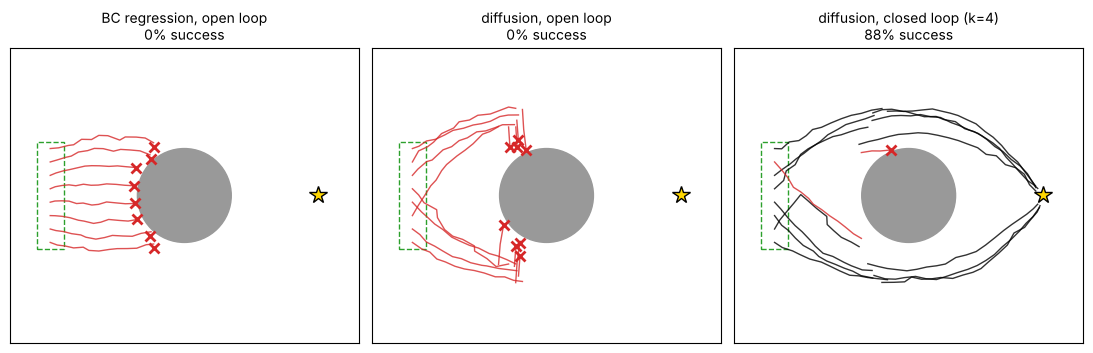

In [16]:
V_MAX = 0.15           # max distance per step (expert steps are ~0.08)
PUSH_STEP = 12
REPLAN_TOL = 0.2       # replan early if this far from the waypoint we were heading for


GOAL_TOL = 0.1         # reaching this close to the goal ends the episode successfully


class PointMass:
    """A batch of kinematic point masses with a speed limit. Crashing into an obstacle and
    reaching the goal are both absorbing: the agent stops there."""

    def __init__(self, starts, obstacles):
        self.x = np.array(starts, dtype=float)
        self.crashed = np.zeros(len(self.x), dtype=bool)
        self.reached = np.zeros(len(self.x), dtype=bool)
        self.obstacles = obstacles

    @property
    def done(self):
        return self.crashed | self.reached

    def step(self, target):
        d = target - self.x
        dist = np.linalg.norm(d, axis=1, keepdims=True)
        x_new = self.x + d * np.minimum(1.0, V_MAX / np.maximum(dist, 1e-9))
        seg = np.stack([self.x, x_new], 1)
        hit = np.zeros(len(self.x), dtype=bool)
        for c, r in self.obstacles:
            hit |= polyline_dist(seg, c) < r
        self.crashed |= hit & ~self.done
        self.x = np.where(self.done[:, None], self.x, x_new)
        self.reached |= ~self.crashed & (np.linalg.norm(self.x - GOAL, axis=1) < GOAL_TOL)


def run_episode(plan_fn, starts, replan_every=None, push=False, n_steps=56,
                obstacles=((OBST_C, OBST_R),)):
    """Roll out a planner in the PointMass world.

    plan_fn(states (B, 2) array) -> plans (B, H, 2) array.
    replan_every=None : open loop, plan once and follow it.
    replan_every=k    : receding horizon, replan every k steps (or when knocked off the plan).
    """
    env = PointMass(starts, obstacles)
    B = len(env.x)
    plan, k = plan_fn(env.x), np.zeros(B, dtype=int)
    target = plan[:, 0]
    path, n_plans = [env.x.copy()], 1
    for step in range(n_steps):
        if push and step == PUSH_STEP:
            env.x[~env.done, 1] *= -1                  # mirror to the other side
            path.append(np.full_like(env.x, np.nan))   # break the drawn line at the jump
            path.append(env.x.copy())
        if replan_every is not None:
            need = (k >= replan_every) | (np.linalg.norm(env.x - target, axis=1) > REPLAN_TOL)
            need &= ~env.done
            if need.any():
                plan[need], k[need] = plan_fn(env.x[need]), 0
                n_plans += 1
        target = plan[np.arange(B), np.minimum(k, H - 1)]
        env.step(target)
        k += 1
        path.append(env.x.copy())
    return {"path": np.stack(path, 1), "crashed": env.crashed, "success": env.reached,
            "n_plans": n_plans}


def bc_planner(states):
    with torch.no_grad():
        return to_paths(bc(to_tensor(states)))


def diffusion_planner(states, **kw):
    return to_paths(sample_plans(policy, to_tensor(states), n_steps=N_STEPS_POLICY, **kw))


def draw_rollouts(ax, res, title):
    draw_world(ax, title=title)
    for p, crashed in zip(res["path"], res["crashed"]):
        ax.plot(p[:, 0], p[:, 1], color=COL["bc"] if crashed else "k", lw=1.0, alpha=0.8)
        if crashed:
            last = p[~np.isnan(p[:, 0])][-1]
            ax.plot(*last, "x", color=COL["bc"], ms=7, mew=2, zorder=6)


roll_starts = np.stack([np.full(8, -1.0), np.linspace(-0.35, 0.35, 8)], 1)
controllers = {"BC regression, open loop": (bc_planner, None),
               "diffusion, open loop": (diffusion_planner, None),
               "diffusion, closed loop (k=4)": (diffusion_planner, 4)}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
torch.manual_seed(0)
for ax, (name, (fn, k)) in zip(axes, controllers.items()):
    res = run_episode(fn, roll_starts, replan_every=k, push=True)
    draw_rollouts(ax, res, f"{name}\n{res['success'].mean():.0%} success")
plt.tight_layout()
plt.show()

Black paths reached the goal, red ones crashed (×); the gaps are the teleport at step 12. After
the push, the open-loop agents steer straight back towards their stale plans, through the
obstacle. The closed-loop agent notices it is off-plan, replans from where it actually is, and
usually just continues along the route on its new side: the multimodal policy offers a good plan
from either side. Let's quantify over many starts, with and without the push.

In [17]:
roll_starts = eval_starts[: (64 if FAST else 300)]
print(f"{'controller':32s} {'no push':>18s} {'with push':>18s}   planner calls")
controllers["BC regression, closed loop (k=4)"] = (bc_planner, 4)
for name, (fn, k) in controllers.items():
    row = []
    for push in [False, True]:
        torch.manual_seed(0)
        res = run_episode(fn, roll_starts, replan_every=k, push=push)
        row.append(f"{res['success'].mean():6.1%} ok {res['crashed'].mean():5.1%} crash")
    print(f"{name:32s} {row[0]:>18s} {row[1]:>18s}   {res['n_plans']}")

controller                                  no push          with push   planner calls
BC regression, open loop          11.0% ok 89.0% crash   0.0% ok 100.0% crash   1


diffusion, open loop              94.7% ok  5.3% crash   1.7% ok 98.3% crash   1


diffusion, closed loop (k=4)      98.0% ok  2.0% crash  98.0% ok  2.0% crash   9
BC regression, closed loop (k=4)  83.7% ok 16.3% crash  83.7% ok 16.3% crash   9


Without perturbations, open-loop diffusion is already good, and replanning changes little.
With the push, open-loop controllers fail (they are executing a plan for a world that no longer
exists) while the receding-horizon diffusion policy recovers in most episodes.

The last row holds a surprise worth understanding: feedback rescues much of *BC* too. Its plan
from an off-centre start leans slightly towards one side; after a few steps the agent is at a
state that, in the demonstrations, is mostly followed by one route, so there the conditional
mean is (nearly) unimodal and safe. Replanning amplifies the small asymmetry, a bit like a ball
rolling off a ridge. BC still crashes from starts near the centre line, where the average stays
ambiguous all the way to the obstacle: the regression policy's failure set shrinks to the
symmetric situations, but it does not vanish, and it would grow with noisier states or modes
that start out closer together. The diffusion policy needs no such luck because it commits to
a mode by *sampling*. Either way, closed loop costs compute: one planning run per replanning step.

## 5 · Planning as inpainting (Diffuser)

The diffusion policy was told the start through its conditioning input. *Diffuser*
(Janner et al. 2022) takes a different view: learn an **unconditional** prior $p(\tau)$ over
whole trajectories $\tau=(w_0,\dots,w_H)$, and impose start and goal at sampling time as
*constraints*, by inpainting (notebook 07). Planning becomes conditional sampling,

$$\tau\sim p(\tau\mid w_0=s,\;w_H=g),$$

and the same network can then plan between *any* start and goal (and, below, satisfy new
constraints) without retraining. We use the **replacement trick**: after every reverse step,
overwrite the known coordinates $y$ with a sample of the forward process at the new noise level,
$\sqrt{\bar\alpha_{t'}}\,y+\sqrt{1-\bar\alpha_{t'}}\,\varepsilon$, so that the network always sees a
consistently-noised trajectory. (Diffuser's own code instead clamps the known states to their
clean values, and trains the network with that clamping.)

Replacement is only approximately right: the unknown coordinates learn about the clamped ones
solely through the network's next prediction, so with few steps the two parts may not agree
("harmonisation" error, notebook 07). RePaint's remedy is to **resample**: after a step
$t\to t'$, diffuse back $t'\to t$ with the forward kernel
$\tau_t=\sqrt{\bar\alpha_t/\bar\alpha_{t'}}\,\tau_{t'}+\sqrt{1-\bar\alpha_t/\bar\alpha_{t'}}\;z$ and
repeat the step, giving the network several chances to make the two parts consistent (the
`resample` option of `sample_plans`). It costs proportionally more network evaluations.

For this we need trajectories with varied starts *and* goals. We reuse the generator with a
taller start box and goals spread along the right-hand side.

In [18]:
WIDE_START = ((-1.1, -0.9), (-0.7, 0.7))
GOAL_BOX = ((0.9, 1.1), (-0.7, 0.7))
traj_demos, traj_route = make_demos(N_DEMOS * 2, np.random.default_rng(4), start_box=WIDE_START,
                                    goal_box=GOAL_BOX)
X_traj = to_tensor(traj_demos).flatten(1)                     # (N, 2(H+1)) whole trajectories
D_TRAJ = X_traj.shape[1]
print("trajectory dataset:", tuple(X_traj.shape))

dm.seed_everything(1)
diffuser_net = TrajectoryDenoiser(D_TRAJ, cond_dim=0).to(device)    # same network, no condition
diffuser = train_denoiser(diffuser_net, X_traj, pred="v", steps=DIFFUSER_STEPS)


def inpaint_plans(model, starts, goals, n_steps=20, resample=1):
    """Sample trajectories whose first and last waypoints are clamped to starts / goals."""
    B = len(starts)
    known = torch.zeros(B, D_TRAJ, device=device)
    mask = torch.zeros(B, D_TRAJ, dtype=torch.bool, device=device)
    known[:, :2], known[:, -2:] = to_tensor(starts), to_tensor(goals)
    mask[:, :2] = mask[:, -2:] = True
    return to_paths(sample_plans(model, None, n=B, n_steps=n_steps, dim=D_TRAJ,
                                 known=known, known_mask=mask, resample=resample))


def seam_ratio(paths):
    """Length of the first and last steps relative to the typical step (1 = seamless)."""
    typical = np.linalg.norm(np.diff(paths[:, 5:-5], axis=1), axis=-1).mean(1)
    ends = (np.linalg.norm(paths[:, 1] - paths[:, 0], axis=1)
            + np.linalg.norm(paths[:, -1] - paths[:, -2], axis=1)) / 2
    return np.median(ends / typical)

trajectory dataset: (4000, 66)


  step  1000 | v-loss 0.1083


  step  2000 | v-loss 0.0990


  step  3000 | v-loss 0.0931


  step  4000 | v-loss 0.0912
  trained in 85 s


**Check.** Unconditional samples should look like the training trajectories, and inpainted
samples must hit their start and goal *exactly* (the last replacement uses $\bar\alpha=1$).
We plan between random start/goal pairs with plain replacement and with 5× resampling.

In [19]:
torch.manual_seed(0)
uncond = to_paths(sample_plans(diffuser, None, n=N_EVAL, n_steps=20, dim=D_TRAJ))
print_metrics("trajectory demos", plan_metrics(traj_demos[:, 0], traj_demos[:, 1:],
                                               goals=traj_demos[:, -1]))
print_metrics("unconditional samples", plan_metrics(uncond[:, 0], uncond[:, 1:],
                                                    goals=uncond[:, -1]))

rng_pairs = np.random.default_rng(5)
pair_starts = np.stack([rng_pairs.uniform(*WIDE_START[0], N_EVAL),
                        rng_pairs.uniform(*WIDE_START[1], N_EVAL)], 1)
pair_goals = np.stack([rng_pairs.uniform(*GOAL_BOX[0], N_EVAL),
                       rng_pairs.uniform(*GOAL_BOX[1], N_EVAL)], 1)
print(f"seam ratio of the demos: {seam_ratio(traj_demos):.2f}")
for resample in [1, 5]:
    torch.manual_seed(0)
    inp = inpaint_plans(diffuser, pair_starts, pair_goals, resample=resample)
    err = max(np.abs(inp[:, 0] - pair_starts).max(), np.abs(inp[:, -1] - pair_goals).max())
    assert err < 1e-5, err
    print_metrics(f"inpainted, resample={resample}", plan_metrics(inp[:, 0], inp[:, 1:], goals=pair_goals))
    print(f"    max endpoint error {err:.1e}, seam ratio {seam_ratio(inp):.2f}")

trajectory demos              collision 0.000  above 0.508  goal err 0.000  roughness  0.0003  spread 0.064
unconditional samples         collision 0.018  above 0.511  goal err 0.000  roughness  0.0004  spread 0.085
seam ratio of the demos: 1.00


inpainted, resample=1         collision 0.019  above 0.514  goal err 0.000  roughness  0.0086  spread 0.082
    max endpoint error 6.0e-08, seam ratio 3.40


inpainted, resample=5         collision 0.000  above 0.511  goal err 0.000  roughness  0.0028  spread 0.053
    max endpoint error 6.0e-08, seam ratio 2.20


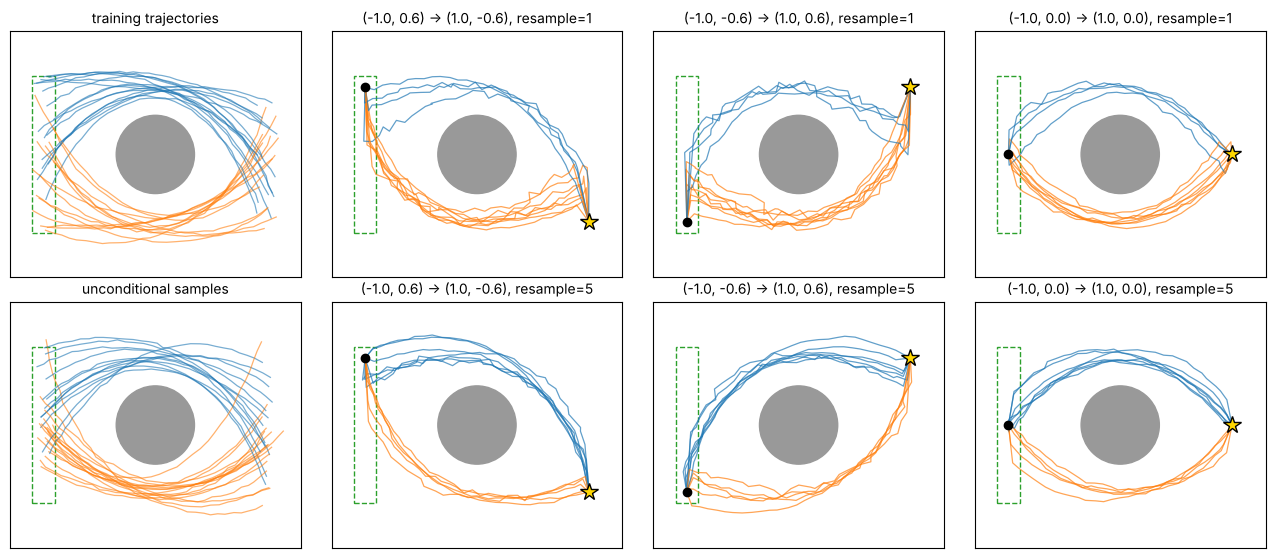

In [20]:
pairs = [((-1.0, 0.6), (1.0, -0.6)), ((-1.0, -0.6), (1.0, 0.6)), ((-1.0, 0.0), (1.0, 0.0))]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))
draw_world(axes[0, 0], title="training trajectories", start_box=WIDE_START, goal=False)
plot_paths(axes[0, 0], traj_demos[:30], alpha=0.6)
draw_world(axes[1, 0], title="unconditional samples", start_box=WIDE_START, goal=False)
plot_paths(axes[1, 0], uncond[:30], alpha=0.6)
for row, resample in enumerate([1, 5]):
    for ax, (s_, g_) in zip(axes[row, 1:], pairs):
        torch.manual_seed(0)
        paths = inpaint_plans(diffuser, np.repeat([s_], 12, 0), np.repeat([g_], 12, 0),
                              resample=resample)
        draw_world(ax, title=f"{s_} -> {g_}, resample={resample}", start_box=WIDE_START, goal=False)
        plot_paths(ax, paths, alpha=0.7)
        ax.plot(*s_, "o", color="k", ms=6, zorder=6)
        ax.plot(*g_, "*", color="gold", mec="k", ms=13, zorder=6)
plt.tight_layout()
plt.show()

The unconditional model has learned "trajectories from somewhere on the left to somewhere on
the right, around the obstacle". Clamping two waypoints turns it into a goal-conditioned
planner, still with both routes, including for start/goal combinations that cross diagonally.
With plain replacement (top row) the clamped endpoints and the rest of the plan do not always
agree: plans begin or end with a jump (a seam ratio well above 1) and are jittery. Resampling
(bottom row) harmonises them at five times the cost: smoother plans and a smaller seam, though
not all the way back to the experts' 1.0 (more resampling, more steps, or reconstruction
guidance would go further).

## 6 · Guidance: a new obstacle at test time

The real power of a generative policy is **composition**. Suppose a new obstacle appears that no
demonstration ever saw. We want plans that are still expert-like but avoid it: samples from

$$\tilde p(\tau\mid s)\;\propto\;p_\theta(\tau\mid s)\,\exp\!\big(-\lambda\,C(\tau)\big),$$

a learned prior times a hand-written "likelihood" $e^{-\lambda C}$, with
$C(\tau)=\sum_j \mathrm{relu}\big(r+m-\lVert w_j-c\rVert\big)^2$ penalising waypoints that come
within $r+m$ of the new obstacle centred at $c$. This is classifier guidance (notebook 06)
with $-\lambda C$ playing the role of $\log p(y\mid\tau)$: the score of the noised target is

$$\nabla_{\tau_t}\log\tilde p_t(\tau_t)=\nabla_{\tau_t}\log p_t(\tau_t\mid s)
+\nabla_{\tau_t}\log\mathbb{E}\big[e^{-\lambda C(\tau_0)}\,\big|\,\tau_t\big].$$

The second term is intractable; the usual approximation (as in DPS, Chung et al. 2023) replaces
$\tau_0$ by its posterior mean $\hat\tau_0(\tau_t)$, giving $-\lambda\nabla_{\tau_t}C(\hat\tau_0)$.
If we further approximate $\partial\hat\tau_0/\partial\tau_t\approx I/\sqrt{\bar\alpha_t}$
(ignoring the network's Jacobian) and convert the score correction into an
$\varepsilon$ correction, $\Delta\varepsilon=-\sqrt{1-\bar\alpha_t}\,\Delta\text{score}$, the
update of $\hat\tau_0=(\tau_t-\sqrt{1-\bar\alpha_t}\,\varepsilon)/\sqrt{\bar\alpha_t}$ is

$$\hat\tau_0\;\leftarrow\;\hat\tau_0-\lambda\,\frac{1-\bar\alpha_t}{\bar\alpha_t}\,\nabla C(\hat\tau_0).$$

We implement the simplest member of this family: a gradient step of *constant* size $\gamma$ on
$\hat\tau_0$, i.e. $\lambda_t=\gamma\,\bar\alpha_t/(1-\bar\alpha_t)=\gamma\cdot\mathrm{SNR}_t$:
weak guidance while the sample is mostly noise, strong guidance near the end. That is the
`cost_fn` hook of `sample_plans`. It is cheap (no backpropagation through the network) and
keeps $\gamma$ interpretable: $\gamma=\tfrac12$ moves a waypoint that penetrates the margin by
exactly its penetration depth.

We put a new obstacle on the lower route and sweep $\gamma$.

In [21]:
NEW_C, NEW_R = np.array([0.45, -0.55]), 0.15
NEW_MARGIN = 0.05
new_c_t = to_tensor(NEW_C)


def new_obstacle_cost(x0):
    """Soft collision penalty of flat plans (B, 2H) with the new obstacle -> (B,)."""
    d = (x0.reshape(x0.shape[0], -1, 2) - new_c_t).norm(dim=-1)
    return F.relu(NEW_R + NEW_MARGIN - d).pow(2).sum(-1)


# check the autograd gradient against the analytic one for a single penetrating waypoint
w = torch.zeros(1, 2 * H, device=device) + 5.0          # all waypoints far away ...
w[0, :2] = to_tensor(NEW_C + np.array([0.05, 0.0]))    # ... except the first: 0.05 from centre
g = cost_gradient(new_obstacle_cost, w)[0, :2].cpu().numpy()
analytic = -2 * (NEW_R + NEW_MARGIN - 0.05) * np.array([1.0, 0.0])
print("autograd grad:", g, " analytic:", analytic)
assert np.allclose(g, analytic, atol=1e-5)

autograd grad: [-0.29999998 -0.        ]  analytic: [-0.3 -0. ]


In [22]:
gammas = [0.0, 0.1, 0.3, 0.5, 1.0, 2.0]
both = ((OBST_C, OBST_R), (NEW_C, NEW_R))
guide_res = []
guide_paths = {}
for gamma in gammas:
    torch.manual_seed(0)
    paths = to_paths(sample_plans(policy, cond_eval, n_steps=20, cost_fn=new_obstacle_cost,
                                  guide=gamma))
    guide_paths[gamma] = paths
    m = plan_metrics(eval_starts, paths)                       # old obstacle only
    m["new collision"] = (polyline_dist(np.concatenate([eval_starts[:, None], paths], 1), NEW_C)
                          < NEW_R).mean()
    m["any collision"] = plan_metrics(eval_starts, paths, obstacles=both)["collision"]
    guide_res.append(m)
    print(f"gamma {gamma:4.2f}: new-obstacle hits {m['new collision']:.3f}  old-obstacle hits "
          f"{m['collision']:.3f}  above {m['above']:.3f}  roughness {m['roughness']:.4f}  "
          f"goal err {m['goal err']:.3f}")

gamma 0.00: new-obstacle hits 0.474  old-obstacle hits 0.016  above 0.498  roughness 0.0011  goal err 0.012


gamma 0.10: new-obstacle hits 0.468  old-obstacle hits 0.017  above 0.498  roughness 0.0012  goal err 0.012


gamma 0.30: new-obstacle hits 0.232  old-obstacle hits 0.017  above 0.498  roughness 0.0016  goal err 0.013


gamma 0.50: new-obstacle hits 0.060  old-obstacle hits 0.017  above 0.498  roughness 0.0022  goal err 0.013


gamma 1.00: new-obstacle hits 0.040  old-obstacle hits 0.017  above 0.498  roughness 0.0028  goal err 0.014


gamma 2.00: new-obstacle hits 0.013  old-obstacle hits 0.037  above 0.498  roughness 0.0051  goal err 0.017


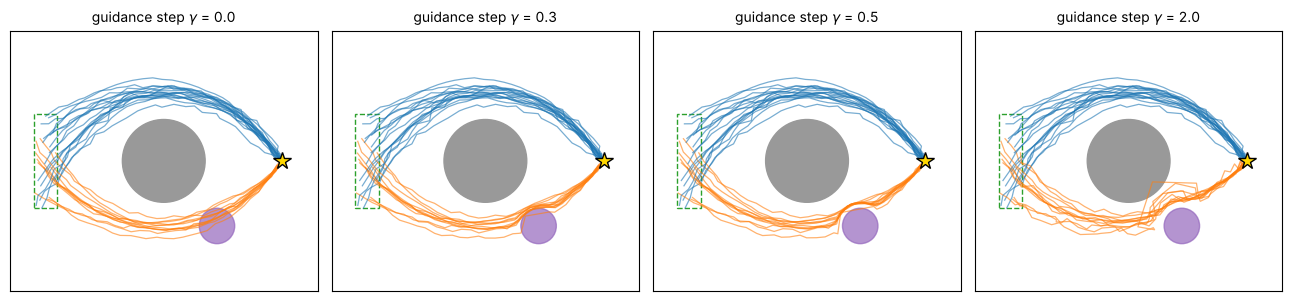

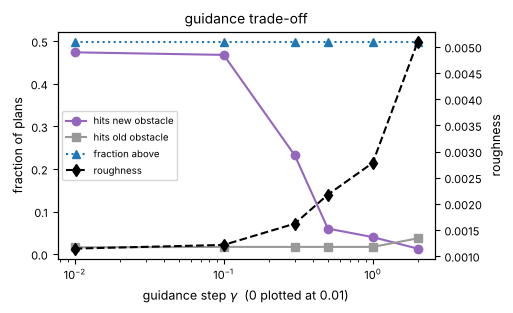

In [23]:
show = [0.0, 0.3, 0.5, 2.0]
fig, axes = plt.subplots(1, len(show), figsize=(13, 2.9))
for ax, gamma in zip(axes, show):
    draw_world(ax, extra_obstacles=[(NEW_C, NEW_R)], title=f"guidance step $\\gamma$ = {gamma}")
    full = np.concatenate([eval_starts[:30, None], guide_paths[gamma][:30]], 1)
    plot_paths(ax, full, alpha=0.6)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5.2, 3.2))
x_g = [max(g_, 0.01) for g_ in gammas]
ax.plot(x_g, [r["new collision"] for r in guide_res], "o-", color=COL["new"], label="hits new obstacle")
ax.plot(x_g, [r["collision"] for r in guide_res], "s-", color=COL["obstacle"], label="hits old obstacle")
ax.plot(x_g, [r["above"] for r in guide_res], "^:", color=COL["above"], label="fraction above")
ax.set_xscale("log")
ax.set_xlabel("guidance step $\\gamma$  (0 plotted at 0.01)")
ax.set_ylabel("fraction of plans")
ax2 = ax.twinx()
ax2.plot(x_g, [r["roughness"] for r in guide_res], "d--", color="k", label="roughness")
ax2.set_ylabel("roughness")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="center left")
ax.set_title("guidance trade-off")
plt.tight_layout()
plt.show()

Without guidance roughly half the plans (those on the lower route) run through the purple
obstacle; the policy has never seen it. With moderate guidance ($\gamma\approx 0.5$) the
lower-route plans bend around it and most collisions disappear, while the upper route is
untouched (its $\hat\tau_0$ never comes near the new obstacle, so the cost gradient is zero).
Pushing harder satisfies the constraint ever more strictly, but each gradient step is blind to
the data distribution: waypoints are shoved radially out of the disc, plans develop kinks and
loops (roughness rises steeply), and the detours start to clip the *old* obstacle. That is the
general guidance trade-off: constraint satisfaction versus staying on the data manifold, and it
is why practical systems use the smallest guidance that does the job.

Notice also what guidance does *not* do: the fraction of plans going above barely changes,
although the upper route is the obvious way to avoid the new obstacle. The route is decided at
low SNR, where $\hat\tau_0$ is (close to) the mean path through the middle, which never touches
the new obstacle; so the point-estimate guidance term is zero exactly when it would matter for
the global choice. When that matters, cheap exact alternatives exist for low-dimensional
decisions: draw many plans and keep those with zero cost (rejection sampling from $\tilde p$
with $\lambda\to\infty$), or weight them by $e^{-\lambda C}$.

In [24]:
torch.manual_seed(0)
raw = guide_paths[0.0]
full = np.concatenate([eval_starts[:, None], raw], 1)
accept = (polyline_dist(full, NEW_C) >= NEW_R) & (polyline_dist(full, OBST_C) >= OBST_R)
print(f"rejection sampling: {accept.mean():.1%} of unguided plans avoid both obstacles; "
      f"accepted plans go above {np.mean(np.array(route_colours(full))[accept] == COL['above']):.1%} of the time")

rejection sampling: 51.0% of unguided plans avoid both obstacles; accepted plans go above 96.1% of the time


### Putting it together: guided, closed-loop control

Guidance composes with everything else, because it only lives inside the sampler. Below, the
closed-loop agent from Section 4 faces the new obstacle (now a real obstacle in the environment)
with and without guidance in its planner.

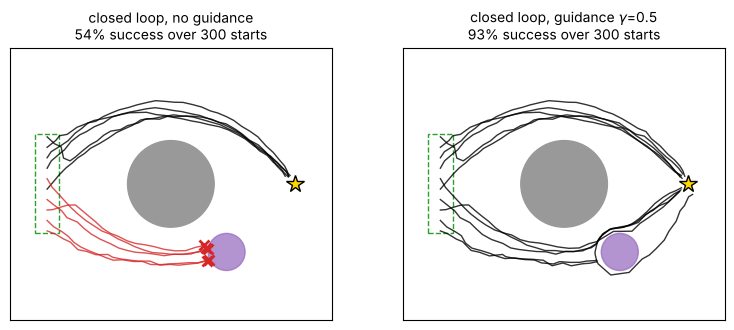

In [25]:
GAMMA = 0.5
guided_planner = lambda s: diffusion_planner(s, cost_fn=new_obstacle_cost, guide=GAMMA)  # noqa: E731
fig, axes = plt.subplots(1, 2, figsize=(8, 3.3))
roll_show = np.stack([np.full(10, -1.0), np.linspace(-0.38, 0.38, 10)], 1)
for ax, (name, fn) in zip(axes, [("closed loop, no guidance", diffusion_planner),
                                 (f"closed loop, guidance $\\gamma$={GAMMA}", guided_planner)]):
    torch.manual_seed(0)
    res = run_episode(fn, roll_show, replan_every=4, obstacles=both)
    stats = run_episode(fn, roll_starts, replan_every=4, obstacles=both)
    draw_rollouts(ax, res, f"{name}\n{stats['success'].mean():.0%} success over "
                           f"{len(roll_starts)} starts")
    ax.add_patch(Circle(NEW_C, NEW_R, color=COL["new"], alpha=0.7, zorder=1))
plt.tight_layout()
plt.show()

The unguided policy happily drives into the obstacle it has never seen; the guided one threads
around it, while still behaving like the experts everywhere else, with no retraining and no new
data. This zero-shot composition of a learned behaviour prior with new objectives is a large
part of why diffusion models became popular in robotics.

## 7 · Discussion: where this goes in practice

**Diffusion Policy** (Chi et al. 2023) is essentially Sections 3–4 at scale: observations are
camera images plus proprioception (encoded by a ResNet and passed as conditioning, with a short
observation history), actions are chunks of end-effector poses, the denoiser is a 1-D temporal
U-Net or a transformer, and execution is receding-horizon with action chunks. Its main selling
points are exactly what we saw: multimodality without mode averaging, stable training (it is
just regression), and the ability to emit high-dimensional, temporally-consistent action chunks.

**Diffuser** (Janner et al. 2022) is Sections 5–6: a trajectory prior over states *and*
actions, conditioning by inpainting, and reward maximisation by guidance with a learned,
noise-aware value function $\nabla_{\tau_t}J_\phi(\tau_t)$ instead of our hand-written cost.

**Decision Diffuser** (Ajay et al. 2023) replaces value guidance by *classifier-free* guidance:
the model is trained conditioned on the return (or on constraints and skills) with label dropout,
and at test time you ask for a high return with $w>1$, exactly as you would ask for a "7" in
notebook 06. It plans over states only and recovers actions with an inverse-dynamics model.

**Limitations.** (i) *Inference cost*: every decision is a multi-step sampling run; few-step
solvers, distillation and consistency-style models are the standard remedies. (ii) *It is still
imitation*: the policy can only be as good as, and only as broad as, the demonstrations;
states far from the data (large perturbations) are out of distribution, and DAgger-style data
collection still matters. (iii) Guidance with a point estimate is local, as we saw; global
constraints need search, sampling-and-filtering, or learning. (iv) Safety cannot be guaranteed
by a soft penalty; real systems add a hard safety layer.

**For cognitive modelling.** A conditional diffusion model is a flexible, likelihood-free
generative model of *behaviour*: trained on human trajectories (mouse-tracking, reaching, eye
movements, navigation), it reproduces their full variability, including several strategies and
probability matching between them, rather than an average. The same machinery supports
inference questions: inpainting the rest of a partially observed trajectory is a posterior
predictive over what an agent will do next, and sampling under different goal conditions and
comparing with what is observed is a route to inverse planning (inferring goals from
behaviour). And "planning as sampling from prior $\times$ $e^{-\text{cost}}$" is the
planning-as-inference view in a new, very expressive guise.

## Exercises

**Exercise 1 (chunk length).** Rerun the push experiment of Section 4 with `replan_every` in
{1, 2, 4, 8, 16, None}, printing the success rate and the number of planner calls. Before you
run it, predict: how much robustness do you lose with long chunks, and what does replanning
every step buy you?

<details><summary>Hint / solution</summary>

Loop over the values and print `res["success"].mean()` and `res["n_plans"]`. In our runs every
value from 1 to 16 succeeded in the large majority of episodes: the early-replanning rule
(`REPLAN_TOL`) catches the push even with long chunks, while pure open loop (`None`) fails.
Compute scales as $1/k$ (56 planner calls per episode at $k=1$). Replanning every step bought
nothing here, and a few episodes at $k=1$ ran out of time without reaching the goal: consecutive
independent samples need not agree, so the agent can hesitate. That effect (temporal
inconsistency between chunks) is why Diffusion Policy executes several actions per chunk; it
is stronger when modes are closer together or the observation is ambiguous. Try turning
`REPLAN_TOL` off (set it to `np.inf`) to see how much the event-triggered replanning matters.
</details>

**Exercise 2 (unbalanced experts).** Make the experts go above 80% of the time
(`side = np.where(rng.random(m) < 0.8, 1.0, -1.0)` in `make_demos`), retrain both policies and
compare. Predict the BC plan and the diffusion route fraction first.

<details><summary>Hint / solution</summary>

Diffusion should match the experts' 80/20 split (probability matching). BC returns the weighted
mean $0.8\mu_{\text{above}}+0.2\mu_{\text{below}}$: with crossing heights of about $\pm0.6$ it
crosses $x=0$ at about $0.6\cdot0.6\approx0.37$, right at the obstacle's edge (radius 0.35),
with none of the margin the experts keep. A posterior *mean* only becomes safe when one mode
dominates overwhelmingly.
</details>

**Exercise 3 (choose the route with classifier-free guidance, à la Decision Diffuser).** Give
`TrajectoryDenoiser` a route label: condition on `torch.cat([s, onehot])` where `onehot` is
(1,0) for above, (0,1) for below and (0,0) for "unknown", drop the label to (0,0) with probability
0.2 during training, and at sampling time combine the two network outputs (CFG is linear, so it
works for $v$ as for $\varepsilon$): $\hat v=\hat v_{\text{u}}+w(\hat v_{\text{c}}-\hat v_{\text{u}})$.
How does the fraction of plans on the requested route depend on $w$?

<details><summary>Hint / solution</summary>

The route label is `route` from `make_demos`, repeated for every window of a demo (the windows
are stacked time-major, so `np.tile(route, H)` lines up with `win_states`). The simplest label
dropout is data duplication: concatenate the training set with a copy whose one-hot is zeroed,
then call `train_denoiser(net, P, cond=torch.cat([S, onehot], 1))` with `cond_dim=4`. In
`sample_plans`, evaluate the network on the conditional and the null condition and combine. With
$w=1$ the requested route should be followed most of the time; $w>1$ pushes towards 100% at some
cost in diversity and smoothness, the same trade-off as in notebook 06.
</details>

**Exercise 4 (the $\tau_0$-model).** Train a third policy with `pred="x0"` (same network and
budget) and add it to the comparison in Section 3, including the figure of samples per start.
Before running: which metrics will improve, and which will get worse?

<details><summary>Hint / solution</summary>

Collisions and roughness can drop to almost zero, but look at the samples: from each start they
fall onto (nearly) two curves, the mean of each route, and the spread collapses. Relative to the
$\varepsilon$-loss, the $\tau_0$-loss down-weights low noise levels by $1/\mathrm{SNR}_t$, and
those are exactly the levels where within-route detail is learned. The network learns *which*
route but otherwise ignores $\tau_t$. A metric that only checks safety would crown this model;
a distributional metric (the spread, or `dm.sliced_wasserstein` against fresh demonstrations from
the same start) exposes it. $v$-prediction sits between the two.
</details>

**Exercise 5 (predicting another agent).** Use the Diffuser model as an observer: clamp the
*first 8 waypoints* of a held-out trajectory (instead of only $w_0$ and $w_H$) and inpaint the
rest. How confidently does the model predict the route as you reveal more of the trajectory
(1, 4, 8, 12 waypoints)?

<details><summary>Hint / solution</summary>

Set `mask[:, :2 * n_obs] = True` and copy the observed waypoints into `known`. The fraction of
completions on each route is a posterior predictive $p(\text{route}\mid w_{0:n})$; it starts near
the prior and sharpens to 0 or 1 as soon as the observed prefix starts curving. This is the
"inverse planning" use of a behaviour model from Section 7, done by inpainting.
</details>

**Exercise 6 (looking inside an $\varepsilon$-network).** Redo the "watching the policy make
up its mind" figure with `policies["eps"]` (pass `pred="eps"` to `sample_plans`). Predict
first: what will $\hat\tau_0$ look like at $t=99$ and $t=68$?

<details><summary>Hint / solution</summary>

The early panels are dominated by noise (clipped to the workspace box). An
$\varepsilon$-network's $\hat\tau_0=(\tau_t-\sqrt{1-\bar\alpha_t}\,\hat\varepsilon)/\sqrt{\bar\alpha_t}$
divides by $\sqrt{\bar\alpha_t}$ ($\approx 0.005$ at $t=99$, $\approx 0.08$ at $t=68$), so small
errors in $\hat\varepsilon$ are magnified 10–200 times. The sampler copes, because the next step
multiplies $\hat\tau_0$ by $\sqrt{\bar\alpha_{t'}}$ again, but anything that *reads*
$\hat\tau_0$ at high noise (a visualisation, the cost guidance of Section 6) sees mostly noise.
With $v$-prediction, $\hat\tau_0=\sqrt{\bar\alpha_t}\,\tau_t-\sqrt{1-\bar\alpha_t}\,\hat v$ is
well-conditioned at every noise level.
</details>

## Key takeaways

- Regression-based behaviour cloning learns $\mathbb{E}[\tau\mid s]$; with multimodal
  demonstrations that mean can be a terrible action (here: through the obstacle).
- A conditional diffusion model over action chunks samples $p(\tau\mid s)$ instead. Its noisiest
  denoiser *is* the BC regressor; the chain of increasingly-informed regressions makes the
  decision between modes, at low SNR.
- The prediction target is a loss weighting over noise levels: $\varepsilon$, $v$ and $\tau_0$
  weight the $\tau_0$-error by $\mathrm{SNR}_t$, $1+\mathrm{SNR}_t$ and $1$. With a small network,
  $\varepsilon$ neglects the low-SNR levels where the route is chosen and $\tau_0$ neglects the
  high-SNR levels where diversity lives; $v$ balances the two. Check diversity, not only safety.
- About 10–20 sampling steps suffice for control. Clip $\hat\tau_0$ to the workspace, decay the
  learning rate, and avoid schedules whose $\bar\alpha_{T-1}$ is nearly zero when predicting
  $\varepsilon$ with few noise levels.
- Receding-horizon execution (sample a chunk, execute part of it, replan, and replan early when
  knocked off the plan) gives robustness to perturbations that open-loop plans lack; the chunk
  length trades reactivity against compute and temporal consistency.
- An *unconditional* trajectory prior becomes a planner by inpainting start and goal (Diffuser);
  RePaint-style resampling removes the seams that plain replacement leaves.
- Cost guidance composes the learned prior with new objectives zero-shot, with a trade-off
  between satisfying the constraint and staying on the data manifold; point-estimate guidance
  acts locally and does not make global (route) decisions.

## Further reading

- C. Chi, S. Feng, Y. Du, Z. Xu, E. Cousineau, B. Burchfiel, S. Song (2023). *Diffusion Policy:
  Visuomotor Policy Learning via Action Diffusion.* RSS. arXiv:2303.04137
- M. Janner, Y. Du, J. Tenenbaum, S. Levine (2022). *Planning with Diffusion for Flexible
  Behavior Synthesis* (Diffuser). ICML. arXiv:2205.09991
- A. Ajay, Y. Du, A. Gupta, J. Tenenbaum, T. Jaakkola, P. Agrawal (2023). *Is Conditional
  Generative Modeling all you need for Decision-Making?* (Decision Diffuser). ICLR. arXiv:2211.15657
- J. Ho, A. Jain, P. Abbeel (2020). *Denoising Diffusion Probabilistic Models.* arXiv:2006.11239
- J. Song, C. Meng, S. Ermon (2021). *Denoising Diffusion Implicit Models.* arXiv:2010.02502
- P. Dhariwal, A. Nichol (2021). *Diffusion Models Beat GANs on Image Synthesis* (classifier
  guidance). arXiv:2105.05233
- J. Ho, T. Salimans (2022). *Classifier-Free Diffusion Guidance.* arXiv:2207.12598
- H. Chung, J. Kim, M. T. Mccann, M. L. Klasky, J. C. Ye (2023). *Diffusion Posterior Sampling
  for General Noisy Inverse Problems* (DPS). ICLR. arXiv:2209.14687
- T. Salimans, J. Ho (2022). *Progressive Distillation for Fast Sampling of Diffusion Models*
  (introduces $v$-prediction). ICLR. arXiv:2202.00512
- D. Kingma, T. Salimans, B. Poole, J. Ho (2021). *Variational Diffusion Models* (loss weighting
  in terms of the SNR). arXiv:2107.00630
- A. Lugmayr, M. Danelljan, A. Romero, F. Yu, R. Timofte, L. Van Gool (2022). *RePaint:
  Inpainting using Denoising Diffusion Probabilistic Models.* CVPR. arXiv:2201.09865
- W. Peebles, S. Xie (2023). *Scalable Diffusion Models with Transformers* (DiT, adaLN
  conditioning). arXiv:2212.09748
- S. Ross, G. Gordon, D. Bagnell (2011). *A Reduction of Imitation Learning and Structured
  Prediction to No-Regret Online Learning* (DAgger). AISTATS.
- S. Levine (2018). *Reinforcement Learning and Control as Probabilistic Inference: Tutorial and
  Review.* arXiv:1805.00909
- B. Efron (2011). *Tweedie's formula and selection bias.* JASA.